# Keyword spotting on an ESP32 (yes / no / left / right)

MohammadMahdi Faraji. Final project of the Machine Learning course (Prof. Hamed Baghban), reworked after the course.

In this notebook I train a small neural network that recognizes four spoken words (yes, no, left, right). Then I convert it to int8, so it can run on an ESP32 with TensorFlow Lite Micro. Besides the four words, the model has two more classes: **silence** and **unknown** (any other word). Without them, the model always picks one of the four words, even when nobody is talking.

Data: Google Speech Commands v0.02 for training and testing, plus 27 short clips that we recorded ourselves with a laptop (me and my roommates).

How to run:
- **Colab:** Runtime → Run all. A GPU runtime makes training faster. At the start you have to upload `own_recordings.zip` (the wav files from `data/own_recordings`), unless you cloned the repo into Colab first. At the end `kws_outputs.zip` is downloaded with the models, plots and the header files for the ESP32.
- **Locally:** install `notebooks/requirements.txt` and run the notebook from the `notebooks` folder.

Main changes compared to my first version (more details in the README):
- train/val/test split by speaker, using the official lists of the dataset, instead of a random split
- exactly 1 second of audio → 49 × 13 MFCC; the padding is done on the audio, not on the MFCC
- the normalization values come only from the training data and are also exported to the ESP32
- a small CNN next to the MLP, and both are quantized to int8
- silence and unknown classes
- the model for the ESP32 is chosen with the validation set; the test set is only used for the final numbers

In [1]:
import os, sys, time, json, hashlib, zipfile, tarfile, shutil, urllib.request, zlib, warnings, contextlib, io
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import tensorflow as tf
import keras
from keras import layers, models, regularizers, callbacks
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

IN_COLAB = 'google.colab' in sys.modules
print('python', sys.version.split()[0], '| numpy', np.__version__, '| librosa', librosa.__version__,
      '| tensorflow', tf.__version__, '| keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

SEED = 42
keras.utils.set_random_seed(SEED)

# folders
WORK = Path('/content') if IN_COLAB else Path('.').resolve()
DATA_DIR = WORK / 'data'
SC_DIR = DATA_DIR / 'speech_commands'
OUT_DIR = WORK / 'outputs'      # everything in here is zipped and downloaded at the end
FIG_DIR = OUT_DIR / 'figures'
FW_DIR = OUT_DIR / 'firmware'   # header files for the ESP32 sketch
for d in [DATA_DIR, OUT_DIR, FIG_DIR, FW_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# classes (the order is important, the ESP32 uses the same order)
KEYWORDS = ['yes', 'no', 'left', 'right']
CLASSES = KEYWORDS + ['silence', 'unknown']
SIL = CLASSES.index('silence')
UNKNOWN_STRIDE = 22   # for "unknown" I use about 1 of every 22 clips of the other 31 words

# audio / MFCC settings
SR = 16000
CLIP_SAMPLES = SR      # 1 second
N_FFT = 512
WIN_LENGTH = 480       # 30 ms
HOP_LENGTH = 320       # 20 ms
N_MELS = 40
N_MFCC = 13
N_FRAMES = 1 + (CLIP_SAMPLES - N_FFT) // HOP_LENGTH   # 49 frames (center=False)
print('model input:', N_FRAMES, 'x', N_MFCC, '| classes:', CLASSES)

python 3.13.15 | numpy 2.1.3 | librosa 0.11.0 | tensorflow 2.21.0 | keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
model input: 49 x 13 | classes: ['yes', 'no', 'left', 'right', 'silence', 'unknown']


## 1. Our own recordings
27 wav files (16 kHz, mono) with the four words, recorded with Audacity on a laptop in our dorm room (with my roommates' permission). They are only used for testing, never for training.

In [2]:
# use the folder of the repo if the notebook runs from a clone (locally, or after git clone in Colab),
# otherwise ask for a zip upload
OWN_DIR = DATA_DIR / 'own_recordings'
candidates = [Path('..') / 'data' / 'own_recordings']
if Path('/content').exists():
    candidates += list(Path('/content').glob('*/data/own_recordings'))
for folder in candidates:
    if folder.is_dir():
        OWN_DIR = folder.resolve()
        break

if not list(OWN_DIR.glob('*.wav')):
    OWN_DIR.mkdir(parents=True, exist_ok=True)
    zip_name = 'own_recordings.zip'
    if IN_COLAB and not Path(zip_name).exists():
        from google.colab import files
        print('please upload own_recordings.zip')
        zip_name = list(files.upload().keys())[0]
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(OWN_DIR)
print(len(list(OWN_DIR.glob('*.wav'))), 'wav files in', OWN_DIR)

please upload own_recordings.zip


Saving own_recordings.zip to own_recordings.zip
27 wav files in /content/data/own_recordings


## 2. Speech Commands dataset
The archive is 2.3 GB, but in Colab the download only takes a few seconds. I only extract what I need:
- the 4 keywords
- about 1/22 of the clips of the other 31 words (for "unknown"). I pick them with a hash of the file name, so it is the same set every time.
- the background noise files
- the lists for the official split

In [3]:
URL = 'https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz'
KEEP_DIRS = KEYWORDS + ['_background_noise_']
KEEP_FILES = ['validation_list.txt', 'testing_list.txt', 'LICENSE']
done_file = SC_DIR / 'extracted.txt'


def keep_file(name):
    folder = name.split('/')[0]
    if folder in KEEP_DIRS or name in KEEP_FILES:
        return True
    # other words: keep about 1 out of UNKNOWN_STRIDE files
    return '/' in name and zlib.crc32(name.encode()) % UNKNOWN_STRIDE == 0


if done_file.exists():
    print('dataset already extracted')
else:
    tar_path = DATA_DIR / 'speech_commands_v0.02.tar.gz'
    if not tar_path.exists():
        print('downloading', URL)
        t0 = time.time()
        urllib.request.urlretrieve(URL, tar_path)
        print(f'done in {time.time() - t0:.0f} s')
    n = 0
    with tarfile.open(tar_path, 'r:gz') as tar:
        for member in tar:
            name = member.name.removeprefix('./')
            if member.isfile() and '..' not in name and keep_file(name):
                dest = SC_DIR / name
                dest.parent.mkdir(parents=True, exist_ok=True)
                with tar.extractfile(member) as src:
                    dest.write_bytes(src.read())
                n += 1
    done_file.write_text('ok')
    tar_path.unlink()   # free 2.3 GB
    print('extracted', n, 'files')

downloading https://storage.googleapis.com/download.tensorflow.org/data/speech_commands_v0.02.tar.gz
done in 99 s
extracted 19685 files


### Split by speaker
Every file name starts with a speaker id (`<speaker>_nohash_<n>.wav`). The dataset comes with `validation_list.txt` and `testing_list.txt`, which put every speaker in only one of train / val / test. These lists cover all 35 words, so the unknown clips are split the same way.

In my first version I used a random split, so the same people were in train and validation, and the accuracy looked better than it really was.

In [4]:
def read_list(name):
    return set((SC_DIR / name).read_text().split())


val_files = read_list('validation_list.txt')
test_files = read_list('testing_list.txt')

rows = []
for folder in sorted(SC_DIR.iterdir()):
    if not folder.is_dir() or folder.name == '_background_noise_':
        continue
    label = folder.name if folder.name in KEYWORDS else 'unknown'
    for wav in sorted(folder.glob('*.wav')):
        rel = folder.name + '/' + wav.name
        if rel in test_files:
            split = 'test'
        elif rel in val_files:
            split = 'val'
        else:
            split = 'train'
        rows.append({'path': str(wav), 'label': label, 'word': folder.name,
                     'speaker': wav.name.split('_nohash_')[0], 'split': split})
meta = pd.DataFrame(rows)
display(pd.crosstab(meta.label, meta.split, margins=True))
print(meta[meta.label == 'unknown'].word.nunique(), 'different words in "unknown"')

# check that no speaker is in two splits
spk = {s: set(meta[meta.split == s].speaker) for s in ['train', 'val', 'test']}
print({s: len(v) for s, v in spk.items()}, 'speakers')
assert not (spk['train'] & spk['val']) and not (spk['train'] & spk['test']) and not (spk['val'] & spk['test'])
print('ok, no speaker is in two splits')

split,test,train,val,All
label,,,,
left,412,3037,352,3801
no,405,3130,406,3941
right,396,3019,363,3778
unknown,427,3272,412,4111
yes,419,3228,397,4044
All,2059,15686,1930,19675


31 different words in "unknown"
{'train': 1938, 'val': 234, 'test': 233} speakers
ok, no speaker is in two splits


## 3. Features
The same functions make the features for training, for testing and for the data that goes to the ESP32. In my first version the ESP32 got the features in a different order than in training, which was one of the bugs.
- `fit_to_1s`: makes every clip exactly 1 s long.
  - Short clips get zeros at the end.
  - Our own clips are longer (1.5–1.8 s), so I cut out the 1 s window around the word, where the energy is.
  - With `mode='start'` it just takes the first second, like my old code did.
- `mfcc_features`: 13 MFCCs with a 30 ms window and a 20 ms hop → 49 frames.

In [5]:
def load_audio(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    return y.astype(np.float32)


def best_window_start(y):
    # energy of every 1 s window (cumulative sum, so it is fast)
    c = np.concatenate([[0.0], np.cumsum(y.astype(np.float64) ** 2)])
    energy = c[CLIP_SAMPLES:] - c[:-CLIP_SAMPLES]
    # all windows with ~max energy contain the whole word -> take the middle one so the word is centered
    good = np.where(energy >= 0.99 * energy.max())[0]
    return int((good[0] + good[-1]) // 2)


def fit_to_1s(y, mode='energy'):
    if len(y) <= CLIP_SAMPLES:
        return np.pad(y, (0, CLIP_SAMPLES - len(y)))
    start = best_window_start(y) if mode == 'energy' else 0
    return y[start:start + CLIP_SAMPLES]


def mfcc_features(y):
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT, win_length=WIN_LENGTH,
                             hop_length=HOP_LENGTH, n_mels=N_MELS, center=False)
    return m.T.astype(np.float32)   # shape (49, 13) = (frames, coefficients)


print('feature shape:', mfcc_features(np.zeros(CLIP_SAMPLES, np.float32)).shape)

feature shape: (49, 13)


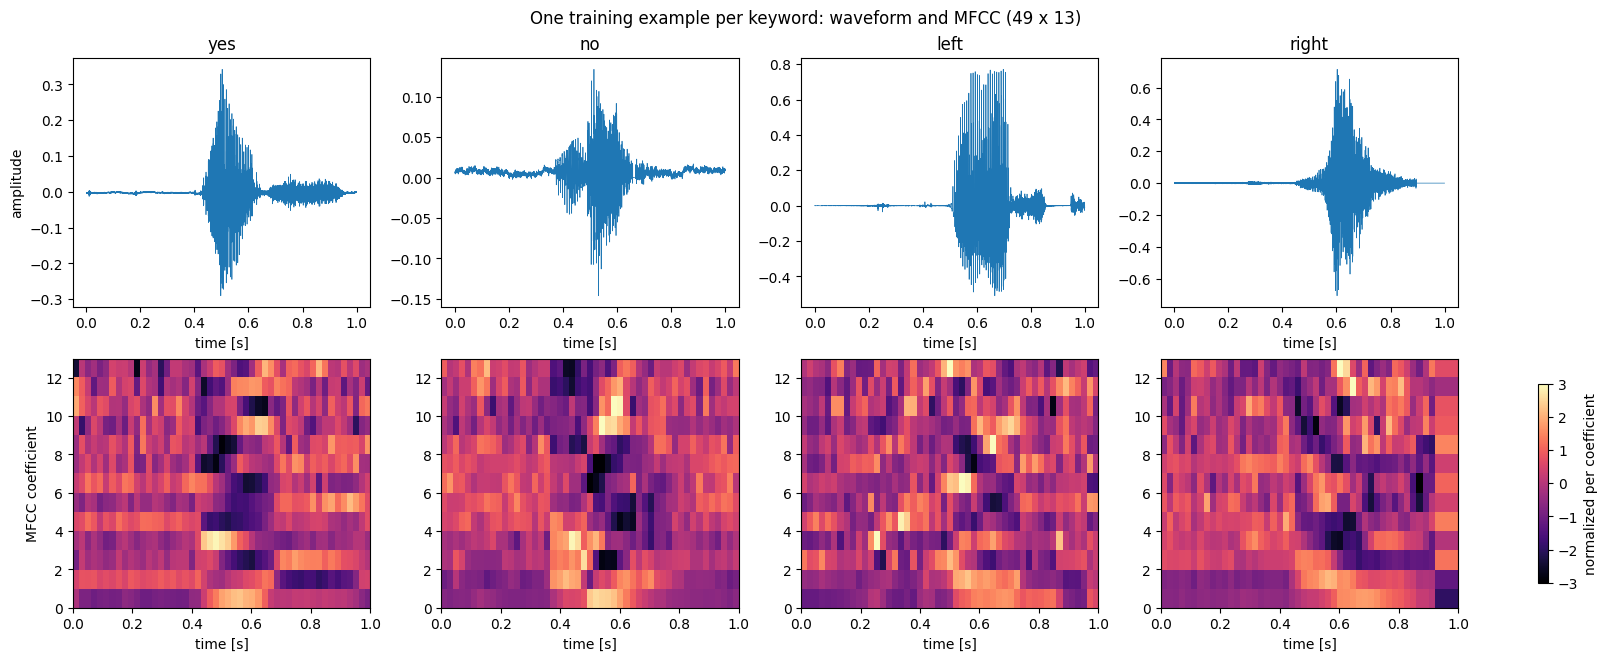

In [6]:
# one training example per keyword
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), constrained_layout=True)
for j, word in enumerate(KEYWORDS):
    path = meta[(meta.label == word) & (meta.split == 'train')].path.iloc[0]
    y = fit_to_1s(load_audio(path))
    axes[0, j].plot(np.arange(len(y)) / SR, y, lw=0.5)
    axes[0, j].set_title(word)
    axes[0, j].set_xlabel('time [s]')
    m = mfcc_features(y).T
    m = (m - m.mean(axis=1, keepdims=True)) / (m.std(axis=1, keepdims=True) + 1e-6)   # only for the plot
    im = axes[1, j].imshow(m, aspect='auto', origin='lower', cmap='magma', extent=[0, 1, 0, N_MFCC], vmin=-3, vmax=3)
    axes[1, j].set_xlabel('time [s]')
axes[0, 0].set_ylabel('amplitude')
axes[1, 0].set_ylabel('MFCC coefficient')
fig.colorbar(im, ax=axes[1, :].tolist(), shrink=0.8, label='normalized per coefficient')
fig.suptitle('One training example per keyword: waveform and MFCC (49 x 13)')
plt.savefig(FIG_DIR / 'examples_mfcc.png', dpi=120, bbox_inches='tight')
plt.show()

## 4. Feature extraction
- **Augmentation:** every keyword / unknown training clip is used twice: the original, and a copy with a random shift (±100 ms) and some background noise added.
- **Silence clips:** 1 s pieces of the 6 background noise files of the dataset, with a random volume. 10 % of them are just zeros (digital silence); our laptop gives exactly this between words.
- **No overlap of noise between splits:** the noise files are split by time (first 80 % train, next 10 % val, last 10 % test), so the test silence does not come from the same parts as the training silence.
- **Cache:** the features are saved in a .npz file, so they don't have to be computed again.

In [7]:
noise_clips = [load_audio(p) for p in sorted((SC_DIR / '_background_noise_').glob('*.wav'))]
print(len(noise_clips), 'noise files')
NOISE_PARTS = {'train': (0.0, 0.8), 'val': (0.8, 0.9), 'test': (0.9, 1.0)}
rng = np.random.default_rng(SEED)


def noise_segment(split, rng):
    # random 1 s piece of a random noise file, only from the part that belongs to this split
    noise = noise_clips[rng.integers(len(noise_clips))]
    lo, hi = NOISE_PARTS[split]
    start = rng.integers(int(lo * len(noise)), int(hi * len(noise)) - CLIP_SAMPLES)
    return noise[start:start + CLIP_SAMPLES]


def augment(y):
    # random time shift of up to 100 ms + some background noise (only for training)
    shift = int(rng.integers(-1600, 1601))
    y = np.roll(y, shift)
    if shift > 0:
        y[:shift] = 0
    elif shift < 0:
        y[shift:] = 0
    y = y + rng.uniform(0.0, 0.1) * noise_segment('train', rng)
    return np.clip(y, -1.0, 1.0).astype(np.float32)


def make_silence(n, split, rng):
    clips = []
    for _ in range(n):
        if rng.random() < 0.1:
            clips.append(np.zeros(CLIP_SAMPLES, np.float32))   # digital silence
        else:
            volume = 10 ** rng.uniform(-3, 0)                   # from very quiet to loud
            clips.append((noise_segment(split, rng) * volume).astype(np.float32))
    return clips

6 noise files


In [8]:
AUG_COPIES = 1


def extract(df, n_aug=0, name=''):
    X, y = [], []
    for i, (path, label) in enumerate(zip(df.path, df.label)):
        audio = fit_to_1s(load_audio(path))
        k = CLASSES.index(label)
        X.append(mfcc_features(audio))
        y.append(k)
        for _ in range(n_aug):
            X.append(mfcc_features(augment(audio)))
            y.append(k)
        if (i + 1) % 2000 == 0:
            print(f'  {name}: {i + 1}/{len(df)}')
    return np.stack(X), np.array(y)


def add_silence(X, y, split, n):
    rng_sil = np.random.default_rng(SEED + len(split))
    S = np.stack([mfcc_features(c) for c in make_silence(n, split, rng_sil)])
    return np.concatenate([X, S]), np.concatenate([y, np.full(n, SIL)])


cache = DATA_DIR / 'features_6class.npz'
if cache.exists():
    d = np.load(cache)
    X_train, y_train, X_val, y_val, X_test, y_test = [d[k] for k in ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']]
    print('loaded features from', cache)
else:
    t0 = time.time()
    data = {}
    for split, n_aug in [('train', AUG_COPIES), ('val', 0), ('test', 0)]:
        df = meta[meta.split == split]
        X, y = extract(df, n_aug, split)
        # as many silence clips as an average keyword has in this split
        n_sil = round(df.label.isin(KEYWORDS).sum() / len(KEYWORDS)) * (1 + n_aug)
        data[split] = add_silence(X, y, split, n_sil)
    X_train, y_train = data['train']
    X_val, y_val = data['val']
    X_test, y_test = data['test']
    np.savez(cache, X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
    print(f'feature extraction took {time.time() - t0:.0f} s')

for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f'{name:5s} {X.shape}  per class: {dict(zip(CLASSES, np.bincount(y, minlength=len(CLASSES)).tolist()))}')

  train: 2000/15686
  train: 4000/15686
  train: 6000/15686
  train: 8000/15686
  train: 10000/15686
  train: 12000/15686
  train: 14000/15686
  test: 2000/2059
feature extraction took 70 s
train (37580, 49, 13)  per class: {'yes': 6456, 'no': 6260, 'left': 6074, 'right': 6038, 'silence': 6208, 'unknown': 6544}
val   (2310, 49, 13)  per class: {'yes': 397, 'no': 406, 'left': 352, 'right': 363, 'silence': 380, 'unknown': 412}
test  (2467, 49, 13)  per class: {'yes': 419, 'no': 405, 'left': 412, 'right': 396, 'silence': 408, 'unknown': 427}


### Normalization
One mean and one std per MFCC coefficient, computed only on the training set. These are just 2 × 13 numbers, and they also go to the ESP32. In my first version the scaler was never saved, so the ESP32 got raw MFCC values.

In [9]:
FEAT_MEAN = X_train.mean(axis=(0, 1)).astype(np.float32)
FEAT_STD = (X_train.std(axis=(0, 1)) + 1e-6).astype(np.float32)


def norm(X):
    return ((X - FEAT_MEAN) / FEAT_STD).astype(np.float32)


Xtr, Xva, Xte = norm(X_train), norm(X_val), norm(X_test)
print('mean:', np.round(FEAT_MEAN, 2))
print('std: ', np.round(FEAT_STD, 2))

mean: [-2.8484e+02  3.5880e+01  3.7500e+00  8.2000e+00 -3.8000e-01  2.5900e+00
 -1.7000e+00  8.9000e-01 -3.0000e-02  8.3000e-01 -3.9000e-01  4.9000e-01
 -2.9000e-01]
std:  [118.09  37.66  17.96  15.41  11.59   9.73   9.16   8.1    6.93   6.68
   6.26   5.66   5.36]


### Energy gate
If a clip is very quiet, the ESP32 doesn't even run the network and just answers "silence".
- **How:** I look at the loudest frame of the first MFCC coefficient (c0), which is basically the loudness of a frame.
- **Threshold:** 50 below the 0.5 % percentile of the training keywords, so normal speech should never be under it.

In [10]:
def c0_max(X):
    return X[:, :, 0].max(axis=1)


kw_c0 = c0_max(X_train[y_train < len(KEYWORDS)])
SILENCE_C0 = float(np.percentile(kw_c0, 0.5) - 50)
print(f'c0 of training keywords: 0.5% percentile {np.percentile(kw_c0, 0.5):.0f}, median {np.median(kw_c0):.0f}')
print(f'gate threshold: {SILENCE_C0:.0f}')
for name, X, y in [('val', X_val, y_val), ('test', X_test, y_test)]:
    kw = y < len(KEYWORDS)
    print(f'{name}: keywords under the threshold {(c0_max(X[kw]) < SILENCE_C0).sum()}/{kw.sum()}, '
          f'silence clips under the threshold {(c0_max(X[y == SIL]) < SILENCE_C0).mean():.0%}')


def apply_gate(X_raw, probs):
    # same rule as on the ESP32: too quiet -> silence with probability 1
    probs = probs.copy()
    probs[c0_max(X_raw) < SILENCE_C0] = np.eye(len(CLASSES))[SIL]
    return probs

c0 of training keywords: 0.5% percentile -265, median -125
gate threshold: -315
val: keywords under the threshold 1/1518, silence clips under the threshold 54%
test: keywords under the threshold 0/1632, silence clips under the threshold 58%


## 5. Models
Both models get the same normalized 49 × 13 input and have 6 outputs.

Training setup:
- Adam with learning rate 1e-3
- early stopping on the validation loss (patience 8)
- the learning rate is halved when the validation loss stops improving

In my first version I used lr = 5e-5, and the model was still improving after 100 epochs.

In [11]:
EPOCHS = 60
BATCH = 64
LR = 1e-3
histories = {}


def plot_history(hist, name):
    epochs = np.arange(1, len(hist['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, key in zip(ax, ['accuracy', 'loss']):
        a.plot(epochs, hist[key], label='train')
        a.plot(epochs, hist['val_' + key], label='validation')
        a.set_title(f'{name} - {key}')
        a.set_xlabel('epoch')
        a.grid(alpha=0.3)
        a.legend()
    plt.savefig(FIG_DIR / f'training_{name}.png', dpi=120, bbox_inches='tight')
    plt.show()


def train(model):
    model.compile(optimizer=keras.optimizers.Adam(LR), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)]
    t0 = time.time()
    h = model.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=EPOCHS, batch_size=BATCH, callbacks=cbs, verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmin(hist['val_loss']))
    print(f"\n{model.name}: {len(hist['loss'])} epochs in {time.time() - t0:.0f} s, best epoch {best + 1}, "
          f"val_loss {hist['val_loss'][best]:.4f}, val_acc {hist['val_accuracy'][best]:.4f}")
    histories[model.name] = hist
    plot_history(hist, model.name)
    return model

### MLP (same architecture as my first version)
Flatten → Dense 128 → Dense 64 → Dense 6, with dropout and L2.

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 637)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        81,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,310 (352.77 KB)

 Trainable params: 90,310 (352.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
588/588 - 9s - 15ms/step - accuracy: 0.5759 - loss: 1.3798 - val_accuracy: 0.7762 - val_loss: 0.8661 - learning_rate: 0.0010
Epoch 2/60
588/588 - 2s - 3ms/step - accuracy: 0.7221 - loss: 0.9819 - val_accuracy: 0.8294 - val_loss: 0.6783 - learning_rate: 0.0010
Epoch 3/60
588/588 - 2s - 3ms/step - accuracy: 0.7687 - loss: 0.8355 - val_accuracy: 0.8537 - val_loss: 0.5870 - learning_rate: 0.0010
Epoch 4/60
588/588 - 2s - 3ms/step - accuracy: 0.7897 - loss: 0.7594 - val_accuracy: 0.8615 - val_loss: 0.5423 - learning_rate: 0.0010
Epoch 5/60
588/588 - 2s - 3ms/step - accuracy: 0.8042 - loss: 0.7094 - val_accuracy: 0.8745 - val_loss: 0.5167 - learning_rate: 0.0010
Epoch 6/60
588/588 - 2s - 3ms/step - accuracy: 0.8156 - loss: 0.6827 - val_accuracy: 0.8758 - val_loss: 0.5051 - learning_rate: 0.0010
Epoch 7/60
588/588 - 2s - 3ms/step - accuracy: 0.8222 - loss: 0.6620 - val_accuracy: 0.8848 - val_loss: 0.4798 - learning_rate: 0.0010
Epoch 8/60
588/588 - 2s - 3ms/step - accuracy: 0.8260 

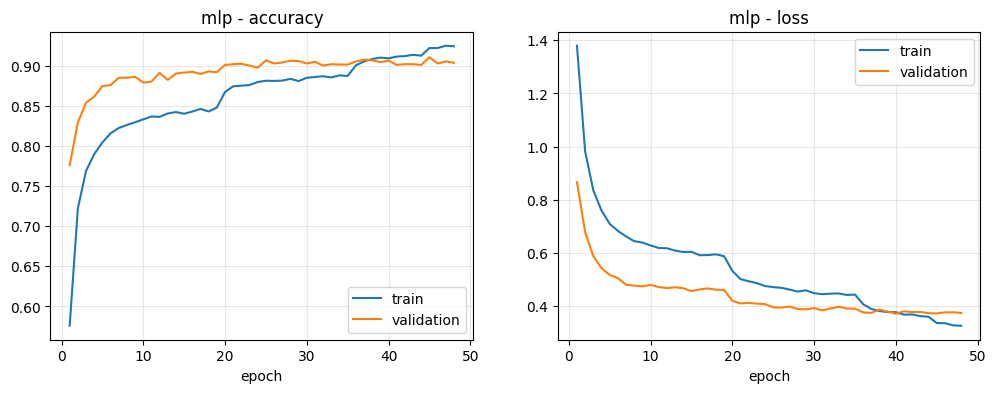

In [12]:
mlp = models.Sequential([
    layers.Input(shape=(N_FRAMES, N_MFCC)),
    layers.Flatten(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dropout(0.3),
    layers.Dense(len(CLASSES), activation='softmax'),
], name='mlp')
mlp.summary()
mlp = train(mlp)

### CNN
The MFCC matrix is used like a small 49 × 13 image. Three 3 × 3 convolution layers, around 51k parameters, which is small enough for the ESP32. Convolutions work better here than the MLP, because a word can start a bit earlier or later.

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 49, 13, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 49, 13, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 6, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 6, 32)      │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 3, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 3, 32)      │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,142 (199.77 KB)

 Trainable params: 51,142 (199.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
588/588 - 14s - 24ms/step - accuracy: 0.7156 - loss: 0.7447 - val_accuracy: 0.8719 - val_loss: 0.3600 - learning_rate: 0.0010
Epoch 2/60
588/588 - 2s - 4ms/step - accuracy: 0.8789 - loss: 0.3490 - val_accuracy: 0.9190 - val_loss: 0.2432 - learning_rate: 0.0010
Epoch 3/60
588/588 - 2s - 4ms/step - accuracy: 0.9042 - loss: 0.2733 - val_accuracy: 0.9156 - val_loss: 0.2300 - learning_rate: 0.0010
Epoch 4/60
588/588 - 2s - 4ms/step - accuracy: 0.9194 - loss: 0.2300 - val_accuracy: 0.9143 - val_loss: 0.2482 - learning_rate: 0.0010
Epoch 5/60
588/588 - 2s - 4ms/step - accuracy: 0.9288 - loss: 0.2013 - val_accuracy: 0.9290 - val_loss: 0.2168 - learning_rate: 0.0010
Epoch 6/60
588/588 - 2s - 4ms/step - accuracy: 0.9364 - loss: 0.1808 - val_accuracy: 0.9195 - val_loss: 0.2390 - learning_rate: 0.0010
Epoch 7/60
588/588 - 2s - 4ms/step - accuracy: 0.9404 - loss: 0.1655 - val_accuracy: 0.9277 - val_loss: 0.2094 - learning_rate: 0.0010
Epoch 8/60
588/588 - 2s - 4ms/step - accuracy: 0.9443

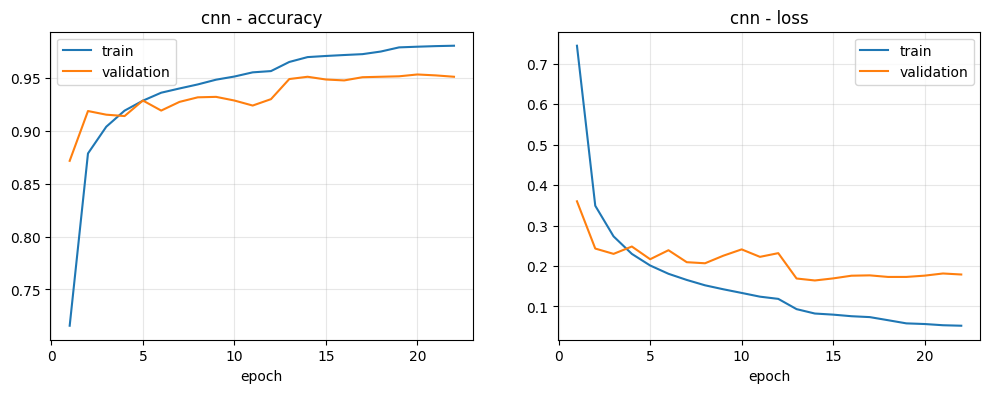

In [13]:
cnn = models.Sequential([
    layers.Input(shape=(N_FRAMES, N_MFCC)),
    layers.Reshape((N_FRAMES, N_MFCC, 1)),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(2),            # -> 24 x 6
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(2),            # -> 12 x 3
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(CLASSES), activation='softmax'),
], name='cnn')
cnn.summary()
cnn = train(cnn)

## 6. Test set results (float32)
The test set has only speakers that are not in train or val. I only use it to report the numbers, not to choose anything.

Besides the normal accuracy, two numbers are important for keyword spotting:
- **keyword accuracy:** how many of the spoken keywords are recognized as the right keyword
- **false alarms:** how many silence / other-word clips are reported as one of the keywords

===== mlp: test accuracy 0.8910, keyword accuracy 0.8934, false alarms 0.1114
              precision    recall  f1-score   support

         yes      0.939     0.924     0.931       419
          no      0.858     0.909     0.882       405
        left      0.855     0.874     0.864       412
       right      0.922     0.866     0.893       396
     silence      0.988     1.000     0.994       408
     unknown      0.790     0.778     0.784       427

    accuracy                          0.891      2467
   macro avg      0.892     0.892     0.892      2467
weighted avg      0.891     0.891     0.891      2467

===== cnn: test accuracy 0.9368, keyword accuracy 0.9442, false alarms 0.0575
              precision    recall  f1-score   support

         yes      0.980     0.957     0.969       419
          no      0.932     0.909     0.920       405
        left      0.938     0.959     0.948       412
       right      0.959     0.952     0.956       396
     silence      0.997     0.

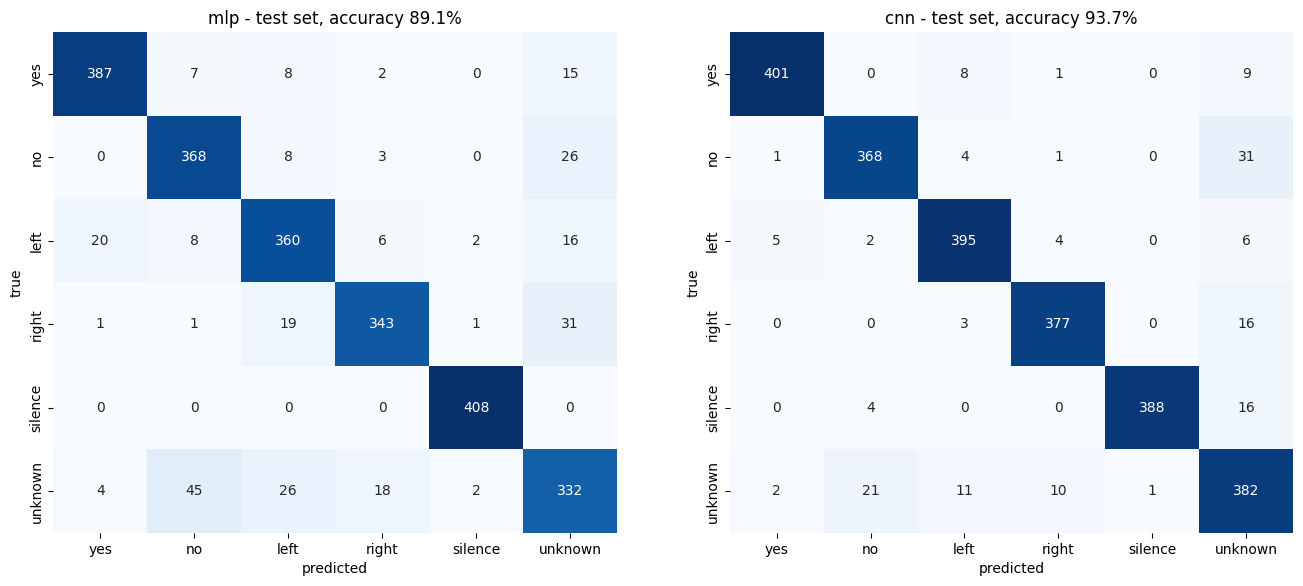

In [14]:
def keyword_metrics(y_true, pred):
    kw = y_true < len(KEYWORDS)
    keyword_acc = (pred[kw] == y_true[kw]).mean()
    false_alarm = (pred[~kw] < len(KEYWORDS)).mean()
    return float(keyword_acc), float(false_alarm)


results = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, model in zip(axes, [mlp, cnn]):
    pred = model.predict(Xte, verbose=0).argmax(1)
    acc = accuracy_score(y_test, pred)
    kw_acc, false_alarm = keyword_metrics(y_test, pred)
    results[model.name] = {'params': int(model.count_params()), 'test_acc_float': float(acc),
                           'keyword_acc_float': kw_acc, 'false_alarm_float': false_alarm}
    print(f'===== {model.name}: test accuracy {acc:.4f}, keyword accuracy {kw_acc:.4f}, false alarms {false_alarm:.4f}')
    print(classification_report(y_test, pred, target_names=CLASSES, digits=3))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'{model.name} - test set, accuracy {acc:.1%}')
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
plt.savefig(FIG_DIR / 'confusion_test.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. int8 quantization
For the ESP32 everything is converted to int8 (weights, activations, input and output), which makes the model about 4× smaller. 500 training samples are used for calibration.

I measure the accuracy again after quantization, because this is the model that really runs on the board. The validation accuracy of the int8 model (with the energy gate) is used to choose which model goes on the ESP32.

Note: newer TensorFlow versions quantize Dense layers per channel. The TFLite Micro version for the ESP32 doesn't support that; I only found this out when I tested on the board. So I turn it off for the Dense layers. The convolutions stay per channel.

In [15]:
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter


def representative_data():
    idx = np.random.default_rng(0).choice(len(Xtr), 500, replace=False)
    for i in idx:
        yield [Xtr[i:i + 1]]


def convert_to_tflite(model, int8):
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if int8:
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8
        converter._experimental_disable_per_channel_quantization_for_dense_layers = True   # see note above
    with contextlib.redirect_stdout(io.StringIO()):   # keras prints a long list of tensors here
        return converter.convert()


def tflite_run(tflite_model, X):
    # runs a tflite model on normalized features and returns the probabilities
    interp = Interpreter(model_content=tflite_model)
    interp.allocate_tensors()
    inp = interp.get_input_details()[0]
    out = interp.get_output_details()[0]
    probs = []
    for x in X:
        x = x[None].astype(np.float32)
        if inp['dtype'] == np.int8:
            scale, zero = inp['quantization']
            x = np.clip(np.round(x / np.float32(scale)) + zero, -128, 127).astype(np.int8)   # float32 like on the ESP32
        interp.set_tensor(inp['index'], x)
        interp.invoke()
        y = interp.get_tensor(out['index'])[0]
        if out['dtype'] == np.int8:
            scale, zero = out['quantization']
            y = (y.astype(np.float32) - zero) * scale
        probs.append(y)
    return np.array(probs)


def dense_is_per_channel(tflite_model):
    # Dense weights are the 2D tensors; per channel means they have more than one scale
    interp = Interpreter(model_content=tflite_model)
    for t in interp.get_tensor_details():
        if len(t['shape']) == 2 and len(t['quantization_parameters']['scales']) > 1:
            return True
    return False


tflite_models = {}
for model in [mlp, cnn]:
    tfl_float = convert_to_tflite(model, int8=False)
    tfl_int8 = convert_to_tflite(model, int8=True)
    assert not dense_is_per_channel(tfl_int8), 'Dense layers are still per channel, the ESP32 cannot run this model'
    tflite_models[model.name] = tfl_int8
    (OUT_DIR / f'{model.name}_int8.tflite').write_bytes(tfl_int8)

    val_pred = apply_gate(X_val, tflite_run(tfl_int8, Xva)).argmax(1)   # used to choose the model
    probs = tflite_run(tfl_int8, Xte)
    pred_int8 = probs.argmax(1)
    pred_deployed = apply_gate(X_test, probs).argmax(1)                 # int8 + energy gate = what the ESP32 does
    kw_acc, false_alarm = keyword_metrics(y_test, pred_deployed)

    r = results[model.name]
    r['float_kb'] = round(len(tfl_float) / 1024, 1)
    r['int8_kb'] = round(len(tfl_int8) / 1024, 1)
    r['val_acc_deployed'] = float(accuracy_score(y_val, val_pred))
    r['test_acc_int8'] = float(accuracy_score(y_test, pred_int8))
    r['test_acc_deployed'] = float(accuracy_score(y_test, pred_deployed))
    r['keyword_acc_deployed'] = kw_acc
    r['false_alarm_deployed'] = false_alarm
    r['input_quant'] = [float(v) for v in Interpreter(model_content=tfl_int8).get_input_details()[0]['quantization']]
    print(f"{model.name}: {r['float_kb']} KB -> {r['int8_kb']} KB | val acc (int8 + gate) {r['val_acc_deployed']:.4f} | "
          f"test acc: float {r['test_acc_float']:.4f}, int8 {r['test_acc_int8']:.4f}, int8 + gate {r['test_acc_deployed']:.4f} | "
          f"keyword acc {kw_acc:.4f}, false alarms {false_alarm:.4f}")

mlp: 355.7 KB -> 92.2 KB | val acc (int8 + gate) 0.9061 | test acc: float 0.8910, int8 0.8914, int8 + gate 0.8910 | keyword acc 0.8971, false alarms 0.1174
cnn: 205.2 KB -> 58.2 KB | val acc (int8 + gate) 0.9524 | test acc: float 0.9368, int8 0.9355, int8 + gate 0.9372 | keyword acc 0.9485, false alarms 0.0719


## 8. Our own recordings
A completely separate test: new speakers, a laptop microphone, a dorm room. All 27 clips contain one of the keywords. If two files are exactly the same, the copy is skipped (in my first version `yes_6` was a copy of `yes_4`).

I test each clip in two ways:
- **start:** the first second, like my old code did
- **energy:** the 1 s window around the word

The int8 models with the energy gate are used here, so this is the same as on the ESP32.

In [16]:
def own_sort_key(p):
    word, num = p.stem.split('_')
    return CLASSES.index(word), int(num)


own = []
seen = {}
for p in sorted(OWN_DIR.glob('*.wav'), key=own_sort_key):
    md5 = hashlib.md5(p.read_bytes()).hexdigest()
    if md5 in seen:
        print(f'skipping {p.name}, it is a copy of {seen[md5]}')
        continue
    seen[md5] = p.name
    own.append(p)
own_y = np.array([CLASSES.index(p.stem.split('_')[0]) for p in own])
own_audio = [load_audio(p) for p in own]
print(len(own), 'recordings')

own_X = {}
for mode in ['start', 'energy']:
    own_X[mode] = np.stack([mfcc_features(fit_to_1s(a, mode)) for a in own_audio])

table = pd.DataFrame({'file': [p.name for p in own], 'true': [CLASSES[k] for k in own_y]})
own_probs = {}
for name in ['mlp', 'cnn']:
    for mode in ['start', 'energy']:
        probs = apply_gate(own_X[mode], tflite_run(tflite_models[name], norm(own_X[mode])))
        pred = probs.argmax(1)
        own_probs[(name, mode)] = probs
        column = []
        for k, p, t in zip(pred, probs.max(1), own_y):
            column.append(f'{CLASSES[k]} {p:.2f}' + ('' if k == t else '  X'))
        table[f'{name} {mode}'] = column
        results[name][f'own_correct_{mode}'] = f'{int((pred == own_y).sum())}/{len(own_y)}'
table.to_csv(OUT_DIR / 'own_recordings_predictions.csv', index=False)
display(table)
for name in ['mlp', 'cnn']:
    print(f"{name}: first 1 s -> {results[name]['own_correct_start']}, window around the word -> {results[name]['own_correct_energy']}")

27 recordings


,file,true,mlp start,mlp energy,cnn start,cnn energy
0,yes_1.wav,yes,yes 1.00,yes 1.00,yes 1.00,yes 1.00
1,yes_2.wav,yes,yes 0.42,yes 0.97,yes 0.99,yes 1.00
2,yes_3.wav,yes,yes 0.68,yes 1.00,yes 1.00,yes 1.00
3,yes_4.wav,yes,yes 1.00,yes 1.00,yes 1.00,yes 1.00
4,yes_5.wav,yes,yes 0.95,yes 1.00,yes 1.00,yes 1.00
5,yes_7.wav,yes,yes 0.73,yes 1.00,yes 1.00,yes 1.00
6,no_3.wav,no,no 0.73,no 0.83,no 1.00,no 1.00
7,no_4.wav,no,no 0.58,no 0.95,no 1.00,no 1.00
8,no_5.wav,no,silence 1.00 X,unknown 0.89 X,silence 1.00 X,unknown 0.93 X
9,no_6.wav,no,silence 1.00 X,no 0.90,silence 1.00 X,no 0.89


mlp: first 1 s -> 20/27, window around the word -> 22/27
cnn: first 1 s -> 24/27, window around the word -> 25/27


word mostly after the first second: ['no_5.wav', 'no_6.wav', 'left_5.wav']


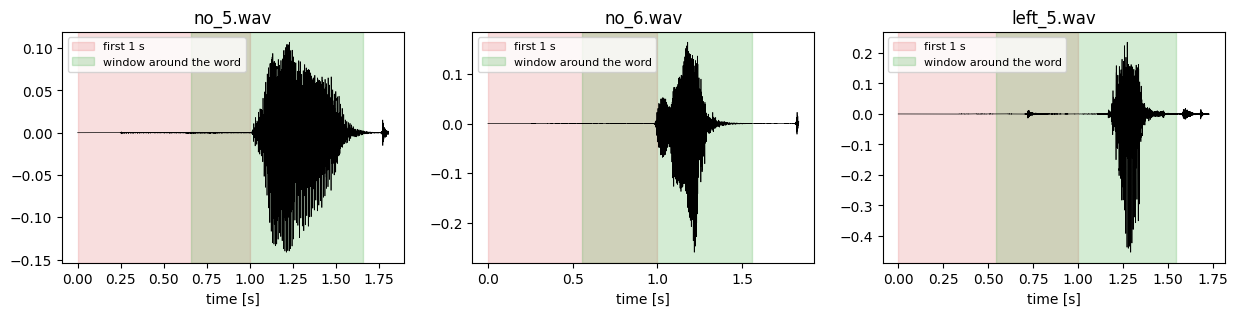

In [17]:
# clips where most of the word is after the first second
late = [i for i, a in enumerate(own_audio) if (a[:CLIP_SAMPLES] ** 2).sum() < 0.5 * (a ** 2).sum()]
print('word mostly after the first second:', [own[i].name for i in late])
if late:
    fig, axes = plt.subplots(1, len(late), figsize=(5 * len(late), 3), squeeze=False)
    for ax, i in zip(axes[0], late):
        a = own_audio[i]
        s = best_window_start(a) / SR
        ax.plot(np.arange(len(a)) / SR, a, lw=0.5, color='k')
        ax.axvspan(0, 1, color='tab:red', alpha=0.15, label='first 1 s')
        ax.axvspan(s, s + 1, color='tab:green', alpha=0.2, label='window around the word')
        ax.set_title(own[i].name)
        ax.set_xlabel('time [s]')
        ax.legend(loc='upper left', fontsize=8)
    plt.savefig(FIG_DIR / 'own_recordings_window.png', dpi=120, bbox_inches='tight')
    plt.show()

## 9. Summary

In [18]:
cols = ['params', 'val_acc_deployed', 'test_acc_float', 'test_acc_int8', 'test_acc_deployed',
        'keyword_acc_deployed', 'false_alarm_deployed', 'int8_kb', 'own_correct_start', 'own_correct_energy']
display(pd.DataFrame(results).T[cols])

metrics = {
    'versions': {'python': sys.version.split()[0], 'numpy': np.__version__, 'librosa': librosa.__version__,
                 'tensorflow': tf.__version__, 'keras': keras.__version__},
    'config': {'classes': CLASSES, 'unknown_stride': UNKNOWN_STRIDE, 'sr': SR, 'n_fft': N_FFT, 'win_length': WIN_LENGTH,
               'hop_length': HOP_LENGTH, 'n_mels': N_MELS, 'n_mfcc': N_MFCC, 'n_frames': N_FRAMES,
               'aug_copies': AUG_COPIES, 'epochs_max': EPOCHS, 'batch': BATCH, 'lr': LR, 'seed': SEED,
               'silence_c0_threshold': SILENCE_C0},
    'split_counts': {name: np.bincount(y, minlength=len(CLASSES)).tolist()
                     for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]},
    'feature_mean': FEAT_MEAN.tolist(),
    'feature_std': FEAT_STD.tolist(),
    'results': results,
    'histories': histories,
    'own_recordings': table.to_dict(orient='records'),
}
with open(OUT_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=1, default=float)   # default=float for numpy numbers
print('saved metrics.json')

,params,val_acc_deployed,test_acc_float,test_acc_int8,test_acc_deployed,keyword_acc_deployed,false_alarm_deployed,int8_kb,own_correct_start,own_correct_energy
mlp,90310,0.906061,0.890961,0.891366,0.890961,0.897059,0.117365,92.2,20/27,22/27
cnn,51142,0.952381,0.936765,0.935549,0.937171,0.948529,0.071856,58.2,24/27,25/27


saved metrics.json


## 10. Export for the ESP32
The model with the better **validation** accuracy goes on the ESP32. The notebook writes three header files, so nothing has to be copied or changed by hand (that was where most of the bugs in my first version came from):
- `model_data.h`: the int8 model as a byte array
- `kws_config.h`: sizes, class names, normalization values and the gate threshold
- `test_samples.h`: the raw MFCCs of our recordings (plus one clip of digital silence), together with what the model predicts here in Python. The ESP32 should print the same.

In [19]:
DEPLOY = max(results, key=lambda n: results[n]['val_acc_deployed'])   # chosen with the validation set, not the test set
print('model for the ESP32:', DEPLOY, '| val acc:', {n: round(r['val_acc_deployed'], 4) for n, r in results.items()})
tfl = tflite_models[DEPLOY]


def c_float(v):
    s = f'{float(v):.9g}'
    if '.' not in s and 'e' not in s:
        s += '.0'
    return s + 'f'


def c_float_list(values, per_line=8, indent='  '):
    vals = [c_float(v) for v in np.ravel(values)]
    lines = [indent + ', '.join(vals[i:i + per_line]) for i in range(0, len(vals), per_line)]
    return ',\n'.join(lines)


# model_data.h
byte_lines = ['  ' + ', '.join(f'0x{b:02x}' for b in tfl[i:i + 12]) for i in range(0, len(tfl), 12)]
model_h = ('// generated by notebooks/keyword_spotting.ipynb\n'
           f'// int8 tflite model ({DEPLOY}), {len(tfl)} bytes\n'
           '// const -> the array stays in flash, alignas(16) is needed by tflite micro\n'
           '#pragma once\n\n'
           'alignas(16) const unsigned char g_model[] = {\n' + ',\n'.join(byte_lines) + '\n};\n'
           f'const unsigned int g_model_len = {len(tfl)};\n')

# kws_config.h
names = ', '.join(f'"{c}"' for c in CLASSES)
config_h = ('// generated by notebooks/keyword_spotting.ipynb\n'
            '#pragma once\n\n'
            f'// features: 16 kHz, 1 s, MFCC with n_fft={N_FFT}, win_length={WIN_LENGTH}, hop_length={HOP_LENGTH}, n_mels={N_MELS}\n'
            f'constexpr int kNumFrames = {N_FRAMES};\n'
            f'constexpr int kNumMfcc = {N_MFCC};\n'
            'constexpr int kFeatureSize = kNumFrames * kNumMfcc;   // order: [frame][coefficient]\n'
            f'constexpr int kNumClasses = {len(CLASSES)};\n'
            f'constexpr int kNumKeywords = {len(KEYWORDS)};   // only the keywords have an LED\n'
            f'constexpr int kSilenceClass = {SIL};\n'
            f'const char* const kClassNames[kNumClasses] = {{{names}}};\n'
            f'#define KWS_MODEL_NAME "{DEPLOY}"\n\n'
            '// energy gate: if the largest c0 of all frames is below this -> silence\n'
            f'constexpr float kSilenceC0Threshold = {c_float(SILENCE_C0)};\n\n'
            '// normalization (from the training set): x_norm = (x - mean[c]) / std[c]\n'
            f'const float kFeatureMean[kNumMfcc] = {{\n{c_float_list(FEAT_MEAN)}\n}};\n'
            f'const float kFeatureStd[kNumMfcc] = {{\n{c_float_list(FEAT_STD)}\n}};\n')

# test_samples.h: our recordings (window around the word) + one clip of digital silence
test_X = np.concatenate([own_X['energy'], mfcc_features(np.zeros(CLIP_SAMPLES, np.float32))[None]])
test_names = [p.stem for p in own] + ['digital_silence']
test_labels = list(own_y) + [SIL]
probs = apply_gate(test_X, tflite_run(tfl, norm(test_X)))
samples = ',\n'.join('  {\n' + c_float_list(x, indent='    ') + '\n  }' for x in test_X)
test_h = ('// generated by notebooks/keyword_spotting.ipynb\n'
          '#pragma once\n#include "kws_config.h"\n\n'
          '// our recordings + one clip of digital silence, raw MFCC values (the ESP32 normalizes them itself)\n'
          f'constexpr int kNumTestSamples = {len(test_names)};\n'
          'const char* const kTestNames[kNumTestSamples] = {' + ', '.join(f'"{n}"' for n in test_names) + '};\n'
          'const int kTestLabels[kNumTestSamples] = {' + ', '.join(str(int(k)) for k in test_labels) + '};\n'
          '// what the same int8 model + gate predicts in Python (the ESP32 should print the same)\n'
          'const int kExpectedPred[kNumTestSamples] = {' + ', '.join(str(int(k)) for k in probs.argmax(1)) + '};\n'
          'const float kExpectedConf[kNumTestSamples] = {' + ', '.join(c_float(v) for v in probs.max(1)) + '};\n\n'
          'const float kTestFeatures[kNumTestSamples][kFeatureSize] = {\n' + samples + '\n};\n')

for fname, text in [('model_data.h', model_h), ('kws_config.h', config_h), ('test_samples.h', test_h)]:
    (FW_DIR / fname).write_text(text, encoding='utf-8')
    print(f'{fname}: {len(text) / 1024:.1f} KB')

model for the ESP32: cnn | val acc: {'mlp': 0.9061, 'cnn': 0.9524}
model_data.h: 359.2 KB
kws_config.h: 1.2 KB
test_samples.h: 238.7 KB


In [20]:
mlp.save(str(OUT_DIR / 'mlp.keras'))
cnn.save(str(OUT_DIR / 'cnn.keras'))
np.savez(OUT_DIR / 'normalisation.npz', mean=FEAT_MEAN, std=FEAT_STD, silence_c0=SILENCE_C0)
archive = shutil.make_archive(str(WORK / 'kws_outputs'), 'zip', OUT_DIR)
print('created', archive)
for p in sorted(OUT_DIR.rglob('*')):
    if p.is_file():
        print('  ', p.relative_to(OUT_DIR))
if IN_COLAB:
    from google.colab import files
    files.download(archive)

created /content/kws_outputs.zip
   cnn.keras
   cnn_int8.tflite
   figures/confusion_test.png
   figures/examples_mfcc.png
   figures/own_recordings_window.png
   figures/training_cnn.png
   figures/training_mlp.png
   firmware/kws_config.h
   firmware/model_data.h
   firmware/test_samples.h
   metrics.json
   mlp.keras
   mlp_int8.tflite
   normalisation.npz
   own_recordings_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
Done. Download the notebook (File → Download → .ipynb), then copy the three header files from `kws_outputs.zip` (folder `firmware`) into `firmware/kws_esp32`.